# Prototype: learning digits from sequence-level labels

The first version of `3_DigitsFromOrder.ipynb`, kept for the record: it is the "earlier prototype" of that notebook's Section 4 (10,000 sequences, both label families). Its outputs are those of its run on a CPU.

**Question.** Can sLTN learn a per-frame digit classifier when the only supervision is a set of labels on whole sequences, with no frame labels?

**Task.** Each example is a sequence of $T = 6$ MNIST images. Each frame's digit is drawn independently and uniformly, so repeats are allowed. The digits are hidden from training. Every sequence comes with 110 binary labels:

- `Contains(c)`, 10 labels: digit $c$ appears somewhere in the sequence.
- `Before(c, c1)`, 100 labels: some $c$ appears at a strictly earlier position than some $c_1$. With $c = c_1$, it means "at least two $c$'s".

**Knowledge.** Two rules link the labels to a frame classifier `digit`:

$$\forall (x, y_c)\; \forall c:\; \mathit{Contains}(y_c, c) \leftrightarrow \exists t:\, \mathit{Is}(\mathit{digit}(x[t]), c)$$

$$\forall (x, y_b)\; \forall c\; \forall c_1:\; \mathit{Before}(y_b, c, c_1) \leftrightarrow \exists t, t_1 \mid \mathit{before}(t, t_1):\, \big(\mathit{Is}(\mathit{digit}(x[t]), c) \wedge \mathit{Is}(\mathit{digit}(x[t_1]), c_1)\big)$$

The $\leftrightarrow$ works in both directions:
- **When a label is true**, the rule only says that *some* frame (or pair of frames) shows the digit. That is weak: it doesn't say which one.
- **When a label is false**, the rule says that *no* frame shows it. That pushes `digit` away from $c$ on every frame of the sequence. Most of the signal comes from these negatives.

**What this prototype does** (plan: `sLTN/docs/application-roadmap.md`, tier 0a):
- both label families, $T = 6$, 10,000 training sequences, one seed;
- $\exists$ computed as **max**, the only aggregator that reproduces the labels exactly (checked in Section 4);
- the default implication (Reichenbach), which also defines $\leftrightarrow$;
- a first look at length generalisation: test sequences of $T = 12$, with no retraining.

**Not done yet:** the GRU baseline, several seeds, the other regimes (fewer sequences, `Before` only, partial labels).

**What to look at:**
- **Frame accuracy** of `digit` on the hidden true digits. This is the headline: chance is 10%.
- **Macro F1** of the sequence labels predicted by the rules, i.e. F1 per label averaged over the 110 labels. Accuracy would mislead here: about 89% of the `Before` labels are false, so answering "always false" scores 89%.
- **Satisfaction** of each rule, reported next to the two metrics above.

In [1]:
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from torchvision import datasets

import sltn
from sltn import Interpretation, KB, Logic, Signature, kb_backward, kb_describe
from sltn.interpretation.operators.aggregator import AggregMax, AggregPMean


def sltn_version():
    # commit, branch and dirty flag of the sLTN checkout in use
    root = Path(sltn.__file__).resolve().parent.parent
    git = lambda *args: subprocess.run(["git", "-C", str(root), *args], capture_output=True, text=True).stdout.strip()
    return dict(commit=git("rev-parse", "HEAD"), branch=git("rev-parse", "--abbrev-ref", "HEAD"),
                dirty=bool(git("status", "--porcelain", "--untracked-files=no")))


CONFIG = dict(
    T=6,               # frames per training sequence
    T_long=12,         # frames per sequence in the length-generalisation test
    n_train=10_000,    # training sequences
    n_val=1_000,
    n_test=2_000,
    batch_size=64,
    epochs=10,
    lr=1e-3,
    exists="max",      # aggregator of ∃ over time
    seed=0,
)
K = 10                 # digit classes

torch.manual_seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("sltn:", sltn_version())

device: cpu
sltn: {'commit': 'fe46a0113d9f137f677cb84a94b621f9fb79ee7c', 'branch': 'bug-fixes-temp', 'dirty': False}


## 1. Data

- **Frames.** MNIST images, scaled to [0, 1]. Training and validation sequences draw their frames from disjoint parts of the MNIST training set (55,000 / 5,000 images). Test sequences draw theirs from the MNIST test set, so no test image was ever seen in training.
- **Sequences.** A sequence is a list of $T$ random image indices. Its true digits come from the MNIST targets. They are used **only** to compute the sequence labels, and later to score `digit`.
- **Labels.** Computed from the true digits:
  - `contains[n, a] = 1` if digit $a$ occurs in sequence $n$;
  - `before[n, a, b] = 1` if some $a$ is at an earlier position than some $b$.

  `earlier[n, t, a]` marks "some $a$ occurs before position $t$". `Before(a, b)` holds iff some position $t$ shows $b$ and has an $a$ earlier.

In [2]:
DATA = "../../datasets/"
mnist_train = datasets.MNIST(DATA, train=True, download=True)
mnist_test = datasets.MNIST(DATA, train=False, download=True)

def to_frames(ds):
    return ds.data.float().div(255).unsqueeze(1), ds.targets     # (N, 1, 28, 28), (N,)

train_imgs, train_digits = to_frames(mnist_train)
test_imgs, test_digits = to_frames(mnist_test)
pools = {
    "train": (train_imgs[:55_000], train_digits[:55_000]),
    "val":   (train_imgs[55_000:], train_digits[55_000:]),
    "test":  (test_imgs, test_digits),
}

def sequence_labels(d):
    # d: (N, T) true digits -> contains (N, K), before (N, K, K)
    oh = F.one_hot(d, K).float()                        # (N, T, K)
    contains = oh.amax(dim=1)
    earlier = (oh.cumsum(dim=1) - oh).clamp(max=1)      # some a strictly before t
    before = torch.einsum("nta,ntb->nab", earlier, oh).clamp(max=1)
    return contains, before

class Sequences:
    # n random sequences of T frames from one pool; frames are looked up lazily
    def __init__(self, pool, n, T, seed):
        imgs, digits = pools[pool]
        g = torch.Generator().manual_seed(seed)
        self.imgs = imgs
        self.idx = torch.randint(0, len(imgs), (n, T), generator=g)
        self.digits = digits[self.idx]                   # hidden: scoring only
        self.contains, self.before = sequence_labels(self.digits)
        self.n, self.T = n, T

    def batches(self, batch_size, shuffle=False, seed=0):
        order = torch.randperm(self.n, generator=torch.Generator().manual_seed(seed)) if shuffle else torch.arange(self.n)
        for s in range(0, self.n, batch_size):
            b = order[s:s + batch_size]
            yield self.imgs[self.idx[b]], self.contains[b], self.before[b], self.digits[b]

S = CONFIG["seed"]
train = Sequences("train", CONFIG["n_train"], CONFIG["T"], seed=1000 + S)
val = Sequences("val", CONFIG["n_val"], CONFIG["T"], seed=2000 + S)
test = Sequences("test", CONFIG["n_test"], CONFIG["T"], seed=3000 + S)
test_long = Sequences("test", CONFIG["n_test"], CONFIG["T_long"], seed=4000 + S)

for name, ds in [("train", train), ("test, T=12", test_long)]:
    print(f"{name:11s}: {ds.n} sequences of {ds.T} frames; positive labels: "
          f"Contains {ds.contains.mean():.2f}, Before {ds.before.mean():.2f}")

train      : 10000 sequences of 6 frames; positive labels: Contains 0.47, Before 0.11
test, T=12 : 2000 sequences of 12 frames; positive labels: Contains 0.72, Before 0.34


A training sequence and some of its labels. The model sees the images and the labels, never the digits printed above the images.

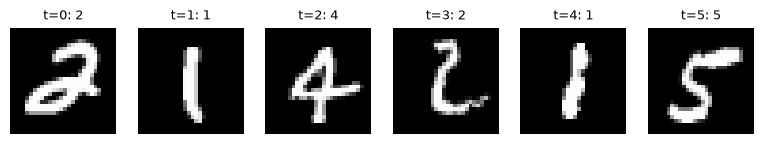

digits (hidden): [2, 1, 4, 2, 1, 5]
Contains true for: [1, 2, 4, 5]
Before true for 11 of 100 pairs: [(1, 1), (1, 2), (1, 4), (1, 5), (2, 1), (2, 2), (2, 4), (2, 5), (4, 1), (4, 2), (4, 5)]


In [3]:
n = 0
fig, axes = plt.subplots(1, CONFIG["T"], figsize=(1.6 * CONFIG["T"], 1.9))
for t, ax in enumerate(axes):
    ax.imshow(train.imgs[train.idx[n, t], 0], cmap="gray")
    ax.set_title(f"t={t}: {train.digits[n, t].item()}", fontsize=9)
    ax.axis("off")
plt.show()
d = train.digits[n].tolist()
print("digits (hidden):", d)
print("Contains true for:", [a for a in range(K) if train.contains[n, a]])
pairs = [(a, b) for a in range(K) for b in range(K) if train.before[n, a, b]]
print(f"Before true for {len(pairs)} of 100 pairs:", pairs)

## 2. Signature: the language, no values yet

- **Sorts.** `Image` (a frame); `Class` (a digit class, as a one-hot vector); `Probs` (the classifier's 10 probabilities); and one sort for each label vector of a sequence (`ContainsLabels`, `BeforeLabels`).
- **`x : Image [T]`.** A sequence: one individual per sequence, with a structural axis over time `T`. `x[t]` is the frame at time `t`.
- **`yc`, `yb`.** The label vectors of the same sequences. `∀ (x, yc)` quantifies over them **together**, sequence by sequence, not over all pairs.
- **`c`, `c1`.** Range over the 10 classes. Both are the same variable `c`; `c1` is an alias, so its values are the same 10 classes.
- **`digit : Image → Probs`.** The classifier being learned. It has no `input_dims`, so it sees one frame at a time: sLTN flattens sequences × time into one batch before calling it.
- **`Is(p, c)`.** How much the probabilities `p` put on class `c`.
- **`Contains`, `Before`.** Read a label from the label vectors.
- **`before(t, t1)`.** A structural relation, true when `t < t1`. It is used as a guard in `∃ t, t1 | before(t, t1): …`.

**Why `digit` is a function.** A predicate `Digit(x[t], c)` would also work. But sLTN calls a predicate once per (frame, class) pair, so the CNN would run 10 times on every frame. As a function, it runs once per frame.

In [4]:
sig = Signature("sequences")
for sort in ("Image", "Class", "Probs", "ContainsLabels", "BeforeLabels"):
    sig.sort(sort)
sig.dimension("T")
sig.variable("x", "Image", dims=["T"])
sig.variable("yc", "ContainsLabels")
sig.variable("yb", "BeforeLabels")
sig.variable("c", "Class")
sig.structural_variable("t", "T")
sig.function("digit", ["Image"], "Probs")
sig.predicate("Is", ["Probs", "Class"])
sig.predicate("Contains", ["ContainsLabels", "Class"])
sig.predicate("Before", ["BeforeLabels", "Class", "Class"])
sig.structural_relation("before", ["T", "T"])

contains_rule = sig.parse("forall (x, yc): forall c: (Contains(yc, c) <-> exists t: Is(digit(x[t]), c))")
before_rule = sig.parse(
    "forall (x, yb): forall c: forall c1: (Before(yb, c, c1) <-> "
    "exists t, t1 | before(t, t1): (Is(digit(x[t]), c) & Is(digit(x[t1]), c1)))"
)
kb = kb_describe(KB([contains_rule, before_rule]))

# The right-hand sides alone: what the rules predict for each label, from `digit`.
contains_pred = sig.parse("exists t: Is(digit(x[t]), c)")
before_pred = sig.parse("exists t, t1 | before(t, t1): (Is(digit(x[t]), c) & Is(digit(x[t1]), c1))")
print("free variables of the Before prediction:", before_pred.free_variables)

KB (2 clauses):
  φ_0: ∀ (x, yc): ∀ c: (Contains(yc, c) ↔ (∃ t: Is(digit(x[t]), c)))
  φ_1: ∀ (x, yb): ∀ c: ∀ c1: (Before(yb, c, c1) ↔ (∃ t, t1 | before(t, t1): (Is(digit(x[t]), c) & Is(digit(x[t1]), c1))))
free variables of the Before prediction: {'x', 'c1', 'c'}


## 3. Interpretation: grounding the language

- **`digit`.** A small CNN with two conv layers and a softmax over the 10 classes, the same shape as the frame encoder of `examples/0`. It is the only trainable part.
- **`Is(p, c)`.** The dot product of the probabilities with the one-hot class, i.e. the probability of class $c$.
- **`Contains`, `Before`.** Look up the label of class $c$, or of the pair $(c, c_1)$, in the label vectors.
- **`c`.** Grounded with the 10 one-hot vectors.
- **`before`.** The strict upper triangle of a $T \times T$ matrix. Each grounding function receives one row per combination of the free variables; the first dimension is that batch.
- **Logic.** The defaults (product ∧, Reichenbach →, pMeanError p = 2 for ∀ and for aggregating the two rules), plus **max** for ∃ over time. Without a structural aggregator, sLTN refuses to evaluate `∃ t`.

In [5]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 28 -> 14
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 14 -> 7
            nn.Flatten(), nn.Linear(32 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, K),
        )

    def forward(self, img):                  # (N, 1, 28, 28) -> (N, K)
        return torch.softmax(self.net(img), dim=-1)

def make_logic(exists):
    logic = Logic().with_defaults()
    logic["exists,t"] = AggregMax() if exists == "max" else AggregPMean(p=exists)
    return logic

def before_relation(T):
    return torch.ones(T, T).triu(diagonal=1)          # before[t, t1] = 1 iff t < t1

def make_interp(digit_fn, image_type, exists):
    it = Interpretation(sig, logic=make_logic(exists))
    it["Image"] = image_type
    it["Class"] = sltn.Type("Class", shape=(K,))
    it["Probs"] = sltn.Type("Probs", shape=(K,))
    it["ContainsLabels"] = sltn.Type("ContainsLabels", shape=(K,))
    it["BeforeLabels"] = sltn.Type("BeforeLabels", shape=(K, K))
    it["digit"] = digit_fn
    it["Is"] = lambda p, c: (p * c).sum(-1, keepdim=True)
    it["Contains"] = lambda y, c: (y * c).sum(-1, keepdim=True)
    it["Before"] = lambda y, c, c1: torch.einsum("nij,ni,nj->n", y, c, c1).unsqueeze(-1)
    it["c"] = torch.eye(K)
    return it

def ground_batch(it, x, contains, before):
    it["x"], it["yc"], it["yb"] = x, contains, before
    it["before"] = before_relation(x.shape[1]).to(x.device)

def by_sequence(result, order):
    # The result's axes are named; reorder them to `order` (e.g. x, c, c1) and drop the truth axis.
    names = [a.name for a in result.axes][:-1]
    return result.value.squeeze(-1).permute(*[names.index(n) for n in order])

print(before_relation(4))

tensor([[0., 1., 1., 1.],
        [0., 0., 1., 1.],
        [0., 0., 0., 1.],
        [0., 0., 0., 0.]])


## 4. Sanity check: with a perfect classifier, do the rules give back the labels?

This check runs before any training. It uses the same signature with a different interpretation: each frame is replaced by the one-hot vector of its true digit, and `digit` is the identity. The rules' right-hand sides should then equal the labels exactly, and both rules should be fully satisfied. If they don't, the knowledge itself is wrong, and no amount of training can fix it.

The check runs with the chosen ∃ (max) and with pMean (p = 2), the aggregator used for ∃ in `examples/0`. With pMean, one true frame pair is averaged with all the false ones, so a true label gets a low value, and that value falls as $T$ grows.

In [6]:
def oracle_check(ds, exists, n=200):
    it = make_interp(lambda v: v, sltn.Type("Image", shape=(K,)), exists)
    x = F.one_hot(ds.digits[:n], K).float()                       # (n, T, K): frames = true one-hots
    ground_batch(it, x, ds.contains[:n], ds.before[:n])
    pc = by_sequence(it(contains_pred), ["x", "c"])
    pb = by_sequence(it(before_pred), ["x", "c", "c1"])
    yb = ds.before[:n]
    return dict(
        exact=bool(torch.equal((pc > 0.5).float(), ds.contains[:n]) and torch.equal((pb > 0.5).float(), yb)),
        before_on_true_min=pb[yb == 1].min().item(),
        before_on_false_max=pb[yb == 0].max().item(),
        sat_contains=it(contains_rule).value.item(),
        sat_before=it(before_rule).value.item(),
    )

for ds in (test, test_long):
    for exists in ("max", 2):
        r = oracle_check(ds, exists)
        print(f"T={ds.T:2d}, exists={str(exists):3s}: labels reproduced {r['exact']!s:5s} | "
              f"Before prediction on true labels >= {r['before_on_true_min']:.2f}, on false <= {r['before_on_false_max']:.2f} | "
              f"sat Contains {r['sat_contains']:.3f}, Before {r['sat_before']:.3f}")

T= 6, exists=max: labels reproduced True  | Before prediction on true labels >= 1.00, on false <= 0.00 | sat Contains 0.999, Before 0.998
T= 6, exists=2  : labels reproduced False | Before prediction on true labels >= 0.26, on false <= 0.00 | sat Contains 0.626, Before 0.762
T=12, exists=max: labels reproduced True  | Before prediction on true labels >= 1.00, on false <= 0.00 | sat Contains 0.999, Before 0.998
T=12, exists=2  : labels reproduced False | Before prediction on true labels >= 0.12, on false <= 0.00 | sat Contains 0.462, Before 0.517


## 5. Training

- **Model and optimiser.** A fresh `DigitCNN`, trained with Adam. The loss is $1 - \mathrm{SatAgg}$ of the two rules, computed by `kb_backward`. It sees the images and the labels, never the digits.
- **Validation, after every epoch:**
  - frame accuracy of `digit`;
  - macro F1 of the labels predicted by the rules' right-hand sides, thresholded at 0.5;
  - satisfaction of each rule.

In [7]:
digit_net = DigitCNN().to(device)
interp = make_interp(digit_net, sltn.Type("Image", shape=(1, 28, 28)), CONFIG["exists"]).to(device)
optimizer = torch.optim.Adam(digit_net.parameters(), lr=CONFIG["lr"])

@torch.no_grad()
def evaluate(ds, batch_size=250):
    digit_net.eval()
    correct, pred_c, pred_b, sats = 0, [], [], {k: [] for k in kb}
    for x, yc, yb, d in ds.batches(batch_size):
        x, yc, yb = x.to(device), yc.to(device), yb.to(device)
        correct += (digit_net(x.flatten(0, 1)).argmax(-1).cpu() == d.flatten()).sum().item()
        ground_batch(interp, x, yc, yb)
        pred_c.append(by_sequence(interp(contains_pred), ["x", "c"]).cpu())
        pred_b.append(by_sequence(interp(before_pred), ["x", "c", "c1"]).cpu())
        for k, phi in kb.items():
            sats[k].append(interp(phi).value.item())
    digit_net.train()
    labels = torch.cat([ds.contains, ds.before.flatten(1)], dim=1).numpy()
    preds = (torch.cat([torch.cat(pred_c), torch.cat(pred_b).flatten(1)], dim=1) > 0.5).numpy()
    return dict(
        frame_acc=correct / ds.digits.numel(),
        f1_contains=f1_score(labels[:, :K], preds[:, :K], average="macro", zero_division=0),
        f1_before=f1_score(labels[:, K:], preds[:, K:], average="macro", zero_division=0),
        f1_all=f1_score(labels, preds, average="macro", zero_division=0),
        sat_contains=float(np.mean(sats["φ_0"])),
        sat_before=float(np.mean(sats["φ_1"])),
    )

def show(tag, m):
    print(f"{tag}: frame acc {m['frame_acc']:.3f} | macro F1 all {m['f1_all']:.3f} "
          f"(Contains {m['f1_contains']:.3f}, Before {m['f1_before']:.3f}) | "
          f"sat Contains {m['sat_contains']:.3f}, Before {m['sat_before']:.3f}")

show("untrained, val", evaluate(val))

untrained, val: frame acc 0.111 | macro F1 all 0.000 (Contains 0.000, Before 0.000) | sat Contains 0.382, Before 0.666


In [8]:
history = []
for epoch in range(1, CONFIG["epochs"] + 1):
    t0, losses = time.perf_counter(), []
    for x, yc, yb, _ in train.batches(CONFIG["batch_size"], shuffle=True, seed=epoch):
        optimizer.zero_grad()
        ground_batch(interp, x.to(device), yc.to(device), yb.to(device))
        stats = kb_backward(optimizer, interp, kb)
        optimizer.step()
        losses.append(stats["agg_loss"])
    m = evaluate(val)
    history.append({"epoch": epoch, "loss": float(np.mean(losses)), **m})
    show(f"epoch {epoch:2d}, loss {np.mean(losses):.4f}, {time.perf_counter() - t0:.0f}s, val", m)

epoch  1, loss 0.2579, 29s, val: frame acc 0.959 | macro F1 all 0.931 (Contains 0.967, Before 0.927) | sat Contains 0.849, Before 0.889


epoch  2, loss 0.1231, 29s, val: frame acc 0.978 | macro F1 all 0.962 (Contains 0.982, Before 0.960) | sat Contains 0.890, Before 0.918


epoch  3, loss 0.0951, 28s, val: frame acc 0.978 | macro F1 all 0.964 (Contains 0.983, Before 0.962) | sat Contains 0.893, Before 0.920


epoch  4, loss 0.0839, 29s, val: frame acc 0.983 | macro F1 all 0.974 (Contains 0.989, Before 0.973) | sat Contains 0.908, Before 0.931


epoch  5, loss 0.0719, 30s, val: frame acc 0.982 | macro F1 all 0.970 (Contains 0.986, Before 0.968) | sat Contains 0.900, Before 0.925


epoch  6, loss 0.0668, 28s, val: frame acc 0.984 | macro F1 all 0.975 (Contains 0.989, Before 0.974) | sat Contains 0.912, Before 0.934


epoch  7, loss 0.0615, 27s, val: frame acc 0.983 | macro F1 all 0.972 (Contains 0.987, Before 0.970) | sat Contains 0.904, Before 0.929


epoch  8, loss 0.0558, 29s, val: frame acc 0.989 | macro F1 all 0.980 (Contains 0.991, Before 0.979) | sat Contains 0.922, Before 0.941


epoch  9, loss 0.0501, 30s, val: frame acc 0.987 | macro F1 all 0.979 (Contains 0.990, Before 0.978) | sat Contains 0.917, Before 0.937


epoch 10, loss 0.0467, 30s, val: frame acc 0.988 | macro F1 all 0.981 (Contains 0.991, Before 0.980) | sat Contains 0.923, Before 0.942


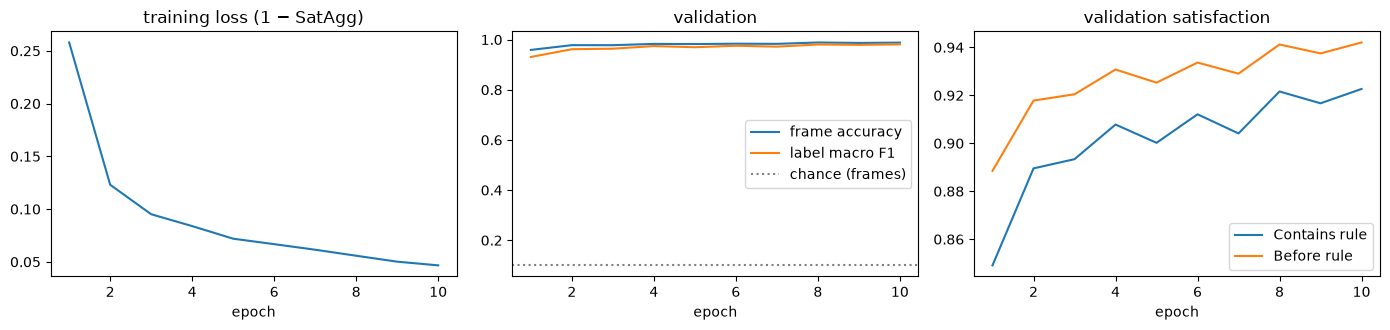

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
ep = [h["epoch"] for h in history]
axes[0].plot(ep, [h["loss"] for h in history]); axes[0].set_title("training loss (1 − SatAgg)")
axes[1].plot(ep, [h["frame_acc"] for h in history], label="frame accuracy")
axes[1].plot(ep, [h["f1_all"] for h in history], label="label macro F1")
axes[1].axhline(0.1, ls=":", c="gray", label="chance (frames)"); axes[1].legend(); axes[1].set_title("validation")
axes[2].plot(ep, [h["sat_contains"] for h in history], label="Contains rule")
axes[2].plot(ep, [h["sat_before"] for h in history], label="Before rule"); axes[2].legend(); axes[2].set_title("validation satisfaction")
for a in axes: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Test

The test sequences use MNIST test images. Two lengths are tested:
- $T = 6$, the training length;
- $T = 12$, with no retraining. Only the `before` relation is regrounded at the new size, because the rules don't mention $T$. Twelve frames give more positive labels (see Section 1), which changes the balance the rules see.

In [10]:
results = {f"test_T{ds.T}": evaluate(ds) for ds in (test, test_long)}
for tag, m in results.items():
    show(tag, m)

test_T6: frame acc 0.988 | macro F1 all 0.981 (Contains 0.992, Before 0.980) | sat Contains 0.921, Before 0.941
test_T12: frame acc 0.988 | macro F1 all 0.985 (Contains 0.994, Before 0.984) | sat Contains 0.916, Before 0.908


Confusion matrix of `digit` on the test frames ($T = 6$). Every class should sit on the diagonal: the labels name the classes, so the model can't learn a permutation of them.

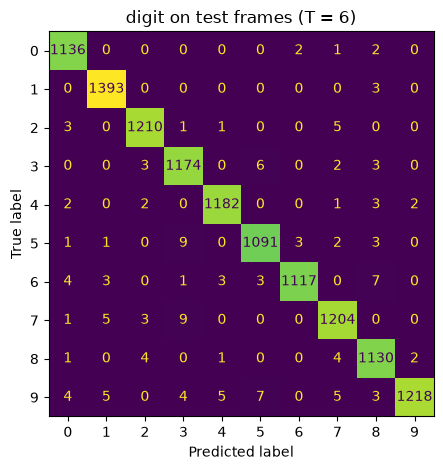

In [11]:
with torch.no_grad():
    digit_net.eval()
    preds = torch.cat([digit_net(x.flatten(0, 1).to(device)).argmax(-1).cpu() for x, *_ in test.batches(250)])
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay.from_predictions(test.digits.flatten(), preds, ax=ax, colorbar=False)
ax.set_title("digit on test frames (T = 6)")
plt.tight_layout(); plt.show()

## 7. Findings

One seed, CPU, 10 epochs: about 29 s per epoch, under 6 minutes in all, at sLTN commit `fe46a01`.

**`digit` is learned from sequence labels alone.**

| | frame accuracy | label macro F1 (Contains / Before) | satisfaction (Contains / Before) |
|---|---|---|---|
| untrained (val) | 0.111 | 0.000 | 0.38 / 0.67 |
| after epoch 1 (val) | 0.959 | 0.931 (0.967 / 0.927) | 0.85 / 0.89 |
| test, T = 6 | **0.988** | 0.981 (0.992 / 0.980) | 0.92 / 0.94 |
| test, T = 12, no retraining | **0.988** | 0.985 (0.994 / 0.984) | 0.92 / 0.91 |

- **No plateau.** Most of the learning happens in the first epoch, 157 steps. `examples/0` stalled for about 200 steps; here the false labels give a signal on every frame from the start.
- **The rules answer correctly at T = 12.** Frame accuracy is the same by construction, since `digit` sees one frame. What the T = 12 row shows is that the rules give the right sequence answers at a length never trained on (macro F1 0.985).
- **Satisfaction isn't accuracy.** With 98.8% of the frames right, the rules are satisfied only to 0.92–0.94. Read satisfaction as a training signal, not as a score.
- **The confusion matrix** is diagonal, as expected, since the labels name the classes.

**What this does and doesn't show.** It shows that the knowledge is correct (the perfect-classifier check reproduces the labels), that `max` for ∃ trains well, and that the pipeline runs end to end. It doesn't show that the knowledge *helps*: 10,000 sequences with both label families make the task easy. That is studied in `3_DigitsFromOrder.ipynb`, with `Before` labels only, 1,000 sequences and a GRU baseline.